# Pipeline Project

You will be using the provided data to create a machine learning model pipeline.

You must handle the data appropriately in your pipeline to predict whether an
item is recommended by a customer based on their review.
Note the data includes numerical, categorical, and text data.

You should ensure you properly train and evaluate your model.

## The Data

The dataset has been anonymized and cleaned of missing values.

There are 8 features for to use to predict whether a customer recommends or does
not recommend a product.
The `Recommended IND` column gives whether a customer recommends the product
where `1` is recommended and a `0` is not recommended.
This is your model's target/

The features can be summarized as the following:

- **Clothing ID**: Integer Categorical variable that refers to the specific piece being reviewed.
- **Age**: Positive Integer variable of the reviewers age.
- **Title**: String variable for the title of the review.
- **Review Text**: String variable for the review body.
- **Positive Feedback Count**: Positive Integer documenting the number of other customers who found this review positive.
- **Division Name**: Categorical name of the product high level division.
- **Department Name**: Categorical name of the product department name.
- **Class Name**: Categorical name of the product class name.

The target:
- **Recommended IND**: Binary variable stating where the customer recommends the product where 1 is recommended, 0 is not recommended.

## Load Data

In [1]:
import pandas as pd

# Load data
df = pd.read_csv(
    'data/reviews.csv',
)

df.info()
df.head()

<class 'pandas.DataFrame'>
RangeIndex: 18442 entries, 0 to 18441
Data columns (total 9 columns):
 #   Column                   Non-Null Count  Dtype
---  ------                   --------------  -----
 0   Clothing ID              18442 non-null  int64
 1   Age                      18442 non-null  int64
 2   Title                    18442 non-null  str  
 3   Review Text              18442 non-null  str  
 4   Positive Feedback Count  18442 non-null  int64
 5   Division Name            18442 non-null  str  
 6   Department Name          18442 non-null  str  
 7   Class Name               18442 non-null  str  
 8   Recommended IND          18442 non-null  int64
dtypes: int64(4), str(5)
memory usage: 1.3 MB


,Clothing ID,Age,Title,Review Text,Positive Feedback Count,Division Name,Department Name,Class Name,Recommended IND
0,1077,60,Some major design flaws,I had such high hopes for this dress and reall...,0,General,Dresses,Dresses,0
1,1049,50,My favorite buy!,"I love, love, love this jumpsuit. it's fun, fl...",0,General Petite,Bottoms,Pants,1
2,847,47,Flattering shirt,This shirt is very flattering to all due to th...,6,General,Tops,Blouses,1
3,1080,49,Not for the very petite,"I love tracy reese dresses, but this one is no...",4,General,Dresses,Dresses,0
4,858,39,Cagrcoal shimmer fun,I aded this in my basket at hte last mintue to...,1,General Petite,Tops,Knits,1


## Preparing features (`X`) & target (`y`)

In [2]:
data = df

# separate features from labels
X = data.drop('Recommended IND', axis=1)
y = data['Recommended IND'].copy()

print('Labels:', y.unique())
print('Features:')
display(X.head())

Labels: [0 1]
Features:


,Clothing ID,Age,Title,Review Text,Positive Feedback Count,Division Name,Department Name,Class Name
0,1077,60,Some major design flaws,I had such high hopes for this dress and reall...,0,General,Dresses,Dresses
1,1049,50,My favorite buy!,"I love, love, love this jumpsuit. it's fun, fl...",0,General Petite,Bottoms,Pants
2,847,47,Flattering shirt,This shirt is very flattering to all due to th...,6,General,Tops,Blouses
3,1080,49,Not for the very petite,"I love tracy reese dresses, but this one is no...",4,General,Dresses,Dresses
4,858,39,Cagrcoal shimmer fun,I aded this in my basket at hte last mintue to...,1,General Petite,Tops,Knits


In [3]:
# Split data into train and test sets
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.1,
    shuffle=True,
    random_state=27,
)

# Your Work

## Data Exploration

All exploration uses the training data only. The test data stays untouched until the final evaluation, so nothing learned here can leak into the test result.

In [4]:
import re

import matplotlib.pyplot as plt
import numpy as np
import spacy
from sklearn.base import BaseEstimator, TransformerMixin
from sklearn.compose import ColumnTransformer
from sklearn.dummy import DummyClassifier
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (ConfusionMatrixDisplay, accuracy_score,
                             classification_report, f1_score,
                             precision_score, recall_score, roc_auc_score)
from sklearn.model_selection import (GridSearchCV, StratifiedKFold,
                                     cross_validate)
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler

RANDOM_STATE = 27
TARGET = 'Recommended IND'
NUMERIC_FEATURES = ['Age', 'Positive Feedback Count']
CATEGORICAL_FEATURES = ['Clothing ID', 'Division Name', 'Department Name',
                        'Class Name']
REVIEW_COLUMN = 'Review Text'
TITLE_COLUMN = 'Title'

In [5]:
def summarize_columns(data):
    """Return the type, missing count and unique count of each column.

    Args:
        data (pandas.DataFrame): The table to summarize.

    Returns:
        pandas.DataFrame: One row per column.
    """
    return pd.DataFrame({
        'dtype': data.dtypes.astype(str),
        'missing': data.isna().sum(),
        'unique': data.nunique(),
    })


print('Training rows:', len(X_train), '| Test rows:', len(X_test))
summarize_columns(X_train)

Training rows: 16597 | Test rows: 1845


,dtype,missing,unique
Clothing ID,int64,0,520
Age,int64,0,76
Title,str,0,11955
Review Text,str,0,16594
Positive Feedback Count,int64,0,76
Division Name,str,0,2
Department Name,str,0,6
Class Name,str,0,14


Share of each class in the training data:
Recommended IND
0    0.184
1    0.816
Name: proportion, dtype: float64


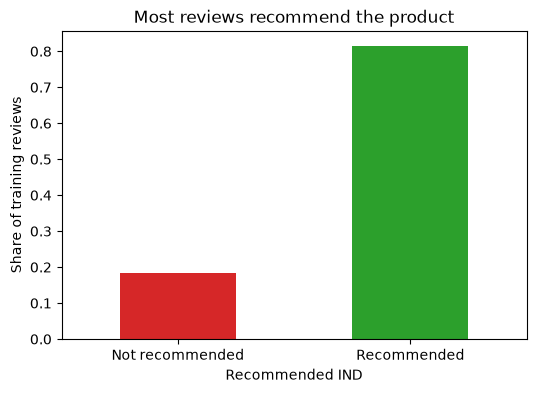

In [6]:
class_share = y_train.value_counts(normalize=True).sort_index()
print('Share of each class in the training data:')
print(class_share.round(3))

ax = class_share.rename({0: 'Not recommended', 1: 'Recommended'}).plot(
    kind='bar', color=['#d62728', '#2ca02c'], rot=0, figsize=(6, 4))
ax.set_title('Most reviews recommend the product')
ax.set_ylabel('Share of training reviews')
plt.show()

In [7]:
X_train[NUMERIC_FEATURES].describe().T.round(1)

,count,mean,std,min,25%,50%,75%,max
Age,16597.0,43.4,12.2,18.0,34.0,42.0,52.0,99.0
Positive Feedback Count,16597.0,2.7,6.0,0.0,0.0,1.0,3.0,122.0


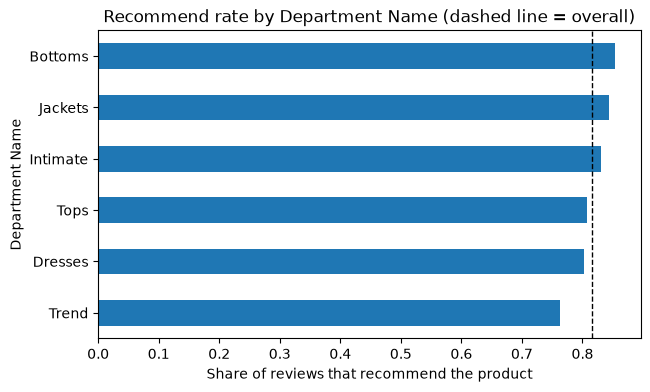

,reviews,recommend_rate
Department Name,,
Trend,97,0.763
Dresses,4845,0.803
Tops,7818,0.807
Intimate,172,0.831
Jackets,813,0.844
Bottoms,2852,0.853


In [8]:
def plot_recommend_rate(features, target, column):
    """Show the share of recommended reviews for each value of a column.

    Args:
        features (pandas.DataFrame): The feature table.
        target (pandas.Series): 1 for recommended, 0 for not recommended.
        column (str): Name of the categorical column to group by.

    Returns:
        pandas.DataFrame: Review count and recommend rate per category.
    """
    table = (target.groupby(features[column]).agg(['count', 'mean'])
             .rename(columns={'count': 'reviews', 'mean': 'recommend_rate'})
             .sort_values('recommend_rate'))
    ax = table['recommend_rate'].plot(kind='barh', figsize=(7, 4),
                                      color='#1f77b4')
    ax.axvline(target.mean(), color='black', linestyle='--', linewidth=1)
    ax.set_title(f'Recommend rate by {column} (dashed line = overall)')
    ax.set_xlabel('Share of reviews that recommend the product')
    plt.show()
    return table.round(3)


plot_recommend_rate(X_train, y_train, 'Department Name')

Words per review, by class:
                   count  mean   50%    max
Recommended IND                            
0                 3062.0  64.1  64.0  111.0
1                13535.0  62.2  62.0  115.0

Clothing IDs: 520 | IDs with fewer than 20 reviews: 375


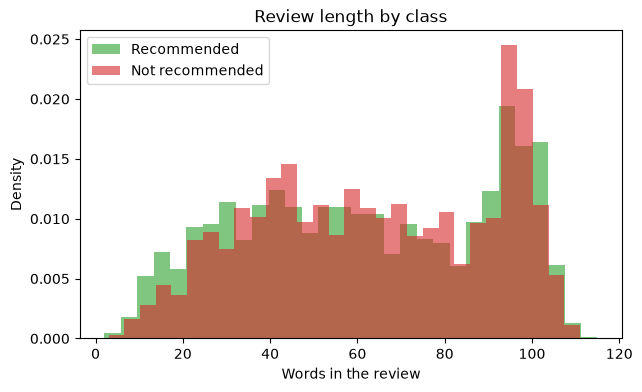

In [9]:
review_words = X_train[REVIEW_COLUMN].str.split().str.len()
length_by_class = review_words.groupby(y_train).describe().round(1)
print('Words per review, by class:')
print(length_by_class[['count', 'mean', '50%', 'max']])
print('\nClothing IDs:', X_train['Clothing ID'].nunique(),
      '| IDs with fewer than 20 reviews:',
      (X_train['Clothing ID'].value_counts() < 20).sum())

fig, ax = plt.subplots(figsize=(7, 4))
for label, name, color in [(1, 'Recommended', '#2ca02c'),
                           (0, 'Not recommended', '#d62728')]:
    ax.hist(review_words[y_train == label], bins=30, alpha=0.6,
            density=True, label=name, color=color)
ax.set_title('Review length by class')
ax.set_xlabel('Words in the review')
ax.set_ylabel('Density')
ax.legend()
plt.show()

**What the exploration shows**

* There are 16,597 training reviews and 1,845 test reviews. No column has missing values. The pipeline still fills gaps, so that it keeps working if new data has some.
* The classes are unbalanced: 81.6% of training reviews recommend the product and 18.4% do not. A model that always answers "recommended" would already be right 81.6% of the time, so accuracy alone is not a good measure.
* `Clothing ID` is a number but it names a product, so it is treated as a category. It has 520 different values and 375 of them have fewer than 20 reviews. One-hot encoding every value would create hundreds of columns that are almost always zero, so values seen fewer than 20 times are grouped together.
* The recommend rate differs a little by department, from 76.3% for Trend (only 97 reviews) to 85.3% for Bottoms. How much the categories add to the prediction is not measured here.
* Recommended and not recommended reviews are about the same length (62.2 and 64.1 words on average). How much review length adds to the prediction, apart from the words themselves, is not measured here.
* `Positive Feedback Count` is strongly skewed: half the reviews have 0 or 1, and the largest value is 122.

## Building Pipeline

The pipeline has one branch for each kind of data, joined by a `ColumnTransformer`, followed by the prediction model. Everything, from cleaning to prediction, lives inside the one pipeline object.

| Branch | Columns | Steps |
|---|---|---|
| Numeric | Age, Positive Feedback Count | fill gaps with the median, then scale |
| Categorical | Clothing ID, Division, Department, Class | fill gaps with the most frequent value, then one-hot encode (rare values grouped) |
| Review words | Review Text | spaCy lemmas, then TF-IDF on words and word pairs |
| Title words | Title | spaCy lemmas, then TF-IDF on words and word pairs |
| Review statistics | Review Text | new features: length and punctuation counts, then scale |
| Review grammar | Review Text | new features: share of adjectives, adverbs, nouns and verbs, and negation count, then scale |

### Text processing with spaCy

Each review is tokenized and lemmatized, so "loved", "loving" and "loves" all become "love". Punctuation, numbers and stop words are dropped. Negations such as "not" and "never" are kept on purpose, because "not flattering" and "flattering" mean opposite things.

spaCy is the slow part of the pipeline, and cross-validation would otherwise repeat it for every fold. `analyze_texts` therefore remembers the result for each text it has already seen. The analysis of a text does not depend on any other text or on the labels, so remembering it cannot leak information between folds.

In [10]:
NLP = spacy.load('en_core_web_sm', disable=['parser', 'ner'])
NEGATIONS = {'no', 'not', 'never', 'none', 'nothing', 'neither', 'nor',
             "n't", 'cannot', 'without'}
POS_TAGS = ['ADJ', 'ADV', 'NOUN', 'VERB']
TEXT_ANALYSIS_CACHE = {}


def clean_text(values):
    """Return the values as a list of strings, with gaps as empty text.

    Args:
        values (array-like): Text values, possibly with missing entries.

    Returns:
        list: One string per value.
    """
    return pd.Series(np.asarray(values, dtype=object).ravel()).fillna(
        '').astype(str).tolist()


def analyze_doc(doc):
    """Turn one spaCy document into lemmas and grammar features.

    Args:
        doc (spacy.tokens.Doc): A processed review.

    Returns:
        tuple: The lemmas joined into one string, and a list holding the
        share of each tag in POS_TAGS followed by the negation count.
    """
    lemmas = []
    tag_counts = dict.fromkeys(POS_TAGS, 0)
    negations = 0
    words = 0
    for token in doc:
        if token.is_punct or token.is_space:
            continue
        words += 1
        lower = token.lower_
        if lower in NEGATIONS:
            negations += 1
            lemmas.append('not' if lower == "n't" else lower)
        elif token.is_alpha and not token.is_stop:
            lemmas.append(token.lemma_.lower())
        if token.pos_ in tag_counts:
            tag_counts[token.pos_] += 1
    shares = [tag_counts[tag] / words if words else 0.0 for tag in POS_TAGS]
    return ' '.join(lemmas), shares + [float(negations)]


def analyze_texts(texts):
    """Run spaCy on the texts not seen before and return every result.

    Args:
        texts (list): Review or title strings.

    Returns:
        list: One (lemma string, grammar features) tuple per text.
    """
    new_texts = [text for text in dict.fromkeys(texts)
                 if text not in TEXT_ANALYSIS_CACHE]
    for text, doc in zip(new_texts, NLP.pipe(new_texts, batch_size=256)):
        TEXT_ANALYSIS_CACHE[text] = analyze_doc(doc)
    return [TEXT_ANALYSIS_CACHE[text] for text in texts]

In [11]:
class SpacyLemmatizer(BaseEstimator, TransformerMixin):
    """Replace each text with its lemmas, keeping negations."""

    def fit(self, X, y=None):
        """Nothing is learned from the data."""
        return self

    def transform(self, X):
        """Return one string of lemmas per text."""
        return [lemmas for lemmas, _ in analyze_texts(clean_text(X))]

    def get_feature_names_out(self, input_features=None):
        """Return the input names unchanged."""
        return input_features


class GrammarFeatures(BaseEstimator, TransformerMixin):
    """Create part-of-speech shares and a negation count from text."""

    def fit(self, X, y=None):
        """Nothing is learned from the data."""
        return self

    def transform(self, X):
        """Return one row of grammar features per text."""
        return np.array([features for _, features
                         in analyze_texts(clean_text(X))])

    def get_feature_names_out(self, input_features=None):
        """Return the names of the created features."""
        names = [f'share_{tag.lower()}' for tag in POS_TAGS]
        return np.array(names + ['negation_count'])


class TextStatistics(BaseEstimator, TransformerMixin):
    """Create length and punctuation features from text."""

    def fit(self, X, y=None):
        """Nothing is learned from the data."""
        return self

    def transform(self, X):
        """Return one row of simple statistics per text."""
        rows = []
        for text in clean_text(X):
            words = text.split()
            longest = max((len(word) for word in words), default=0)
            rows.append([len(text), len(words), text.count('!'),
                         text.count('?'), longest])
        return np.array(rows, dtype=float)

    def get_feature_names_out(self, input_features=None):
        """Return the names of the created features."""
        return np.array(['character_count', 'word_count',
                         'exclamation_count', 'question_count',
                         'longest_word_length'])

In [12]:
def build_text_branch(min_df):
    """Return a pipeline that lemmatizes text and builds TF-IDF features.

    Args:
        min_df (int): Ignore terms that appear in fewer documents.

    Returns:
        sklearn.pipeline.Pipeline: Lemmatizer followed by TF-IDF.
    """
    return Pipeline([
        ('lemmatize', SpacyLemmatizer()),
        ('tfidf', TfidfVectorizer(ngram_range=(1, 2), min_df=min_df,
                                  sublinear_tf=True)),
    ])


def build_pipeline():
    """Return the full pipeline, from raw columns to the prediction model.

    Returns:
        sklearn.pipeline.Pipeline: Preprocessing, feature creation and a
        logistic regression classifier.
    """
    numeric = Pipeline([
        ('impute', SimpleImputer(strategy='median')),
        ('scale', StandardScaler()),
    ])
    categorical = Pipeline([
        ('impute', SimpleImputer(strategy='most_frequent')),
        ('encode', OneHotEncoder(handle_unknown='infrequent_if_exist',
                                 min_frequency=20)),
    ])
    review_statistics = Pipeline([
        ('statistics', TextStatistics()),
        ('scale', StandardScaler()),
    ])
    review_grammar = Pipeline([
        ('grammar', GrammarFeatures()),
        ('scale', StandardScaler()),
    ])
    preprocess = ColumnTransformer([
        ('numeric', numeric, NUMERIC_FEATURES),
        ('categorical', categorical, CATEGORICAL_FEATURES),
        ('review_words', build_text_branch(min_df=3), REVIEW_COLUMN),
        ('title_words', build_text_branch(min_df=2), TITLE_COLUMN),
        ('review_statistics', review_statistics, REVIEW_COLUMN),
        ('review_grammar', review_grammar, REVIEW_COLUMN),
    ])
    model = LogisticRegression(solver='liblinear', max_iter=2000,
                               random_state=RANDOM_STATE)
    return Pipeline([('preprocess', preprocess), ('model', model)])


pipeline = build_pipeline()
pipeline

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('preprocess', ...), ('model', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('numeric', ...), ('categorical', ...), ...]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthrough'``, all remaining columns thatwere not specified in `transformers`, but present in the data passedto `fit` will be automatically passed through. This subset of columnsis concatenated with the output of the transformers. For dataframes,extra columns not seen during `fit` will be excluded from the outputof `transform`.By setting ``remainder`` to be an estimator, the remainingnon-specified columns will use the ``remainder`` estimator. Theestimator must support :term:`fit` and :term:`transform`.Note that using this feature requires that the DataFrame columnsinput at :term:`fit` and :term:`transform` have identical order.",'drop'
,"sparse_threshold sparse_threshold: float, de

A quick look at what the text steps produce for two made-up reviews:

In [13]:
examples = ["I LOVED this dress! It wasn't too tight and fits perfectly.",
            'The fabric is not flattering and the colors were dull.']
for example, (lemmas, grammar) in zip(examples, analyze_texts(examples)):
    print('Review :', example)
    print('Lemmas :', lemmas)
    names = GrammarFeatures().get_feature_names_out()
    print('Grammar:', ', '.join(f'{name}={value:.2f}'
                                for name, value in zip(names, grammar)))
    print()

Review : I LOVED this dress! It wasn't too tight and fits perfectly.
Lemmas : love dress not tight fit perfectly
Grammar: share_adj=0.08, share_adv=0.17, share_noun=0.08, share_verb=0.17, negation_count=1.00

Review : The fabric is not flattering and the colors were dull.
Lemmas : fabric not flattering color dull
Grammar: share_adj=0.20, share_adv=0.00, share_noun=0.20, share_verb=0.00, negation_count=1.00



## Training Pipeline

The pipeline is trained with the training data only. Before any tuning, five-fold cross-validation on the training data gives an honest first estimate, next to a baseline that always predicts the most common class.

Because 82% of reviews recommend the product, accuracy alone is misleading: the baseline scores well without learning anything. This project assumes that finding the reviews that do **not** recommend a product matters to the business, so precision, recall and F1 are reported for both classes, and macro F1 (the plain average of the two classes' F1 scores) is the headline measure.

In [14]:
SCORING = {'accuracy': 'accuracy', 'macro_f1': 'f1_macro',
           'roc_auc': 'roc_auc'}
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)


def cross_validated_scores(estimator, features, target):
    """Return the mean cross-validated scores of an estimator.

    Args:
        estimator: An unfitted scikit-learn estimator or pipeline.
        features (pandas.DataFrame): Training features.
        target (pandas.Series): Training labels.

    Returns:
        pandas.Series: Mean test score for each measure in SCORING.
    """
    result = cross_validate(estimator, features, target, cv=cv,
                            scoring=SCORING)
    return pd.Series({name: result[f'test_{name}'].mean()
                      for name in SCORING})


baseline = DummyClassifier(strategy='most_frequent')
cv_scores = pd.DataFrame({
    'Baseline (always recommended)': cross_validated_scores(
        baseline, X_train, y_train),
    'Pipeline (default settings)': cross_validated_scores(
        pipeline, X_train, y_train),
}).T.round(3)
print('Texts analyzed by spaCy so far:', len(TEXT_ANALYSIS_CACHE))
cv_scores

Texts analyzed by spaCy so far: 28547


,accuracy,macro_f1,roc_auc
Baseline (always recommended),0.816,0.449,0.500
Pipeline (default settings),0.904,0.825,0.949


In [15]:
pipeline.fit(X_train, y_train)
feature_count = pipeline.named_steps['preprocess'].transform(
    X_train.head()).shape[1]
print('Features created by the preprocessing step:', feature_count)
print('Training accuracy:', round(pipeline.score(X_train, y_train), 3))

Features created by the preprocessing step: 33641


Training accuracy: 0.948


**First results (cross-validation on the training data)**

* The baseline has 81.6% accuracy but a macro F1 of only 0.449 and a ROC AUC of 0.500, because it never finds a single "not recommended" review.
* The pipeline with default settings reaches 90.4% accuracy, a macro F1 of 0.825 and a ROC AUC of 0.949.
* The preprocessing step turns the 8 input columns into 33,641 features. Almost all of them are TF-IDF terms from the review text and the title.
* Accuracy on the training data itself is 94.8%, against 90.4% in cross-validation. The gap shows some overfitting, which is expected with this many text features, and it is one reason to tune the strength of the regularization next.

## Fine-Tuning Pipeline

A grid search with five-fold cross-validation, on the training data only, tries 12 combinations of three settings:

* `C`: how strongly the logistic regression is regularized (smaller means stronger).
* `class_weight`: whether the rarer "not recommended" class is given more weight.
* `ngram_range` of the review text: single words only, or words and word pairs.

The search optimizes macro F1, for the reason given above. `GridSearchCV` then refits the best combination on all of the training data.

In [16]:
param_grid = {
    'model__C': [0.3, 1, 3],
    'model__class_weight': [None, 'balanced'],
    'preprocess__review_words__tfidf__ngram_range': [(1, 1), (1, 2)],
}
search = GridSearchCV(build_pipeline(), param_grid, scoring='f1_macro',
                      cv=cv, refit=True)
search.fit(X_train, y_train)

print('Best settings:', search.best_params_)
print('Best cross-validated macro F1:', round(search.best_score_, 3))

Best settings: {'model__C': 3, 'model__class_weight': 'balanced', 'preprocess__review_words__tfidf__ngram_range': (1, 2)}
Best cross-validated macro F1: 0.851


In [17]:
results = pd.DataFrame(search.cv_results_)
results = results.rename(columns={
    'param_model__C': 'C',
    'param_model__class_weight': 'class_weight',
    'param_preprocess__review_words__tfidf__ngram_range': 'ngram_range',
    'mean_test_score': 'mean_macro_f1',
    'std_test_score': 'std_macro_f1',
})
columns = ['C', 'class_weight', 'ngram_range', 'mean_macro_f1',
           'std_macro_f1', 'rank_test_score']
results[columns].sort_values('rank_test_score').round(3)

,C,class_weight,ngram_range,mean_macro_f1,std_macro_f1,rank_test_score
11,3.0,balanced,"(1, 2)",0.851,0.007,1
7,1.0,balanced,"(1, 2)",0.844,0.006,2
10,3.0,balanced,"(1, 1)",0.843,0.007,3
6,1.0,balanced,"(1, 1)",0.841,0.007,4
9,3.0,NaN,"(1, 2)",0.837,0.005,5
8,3.0,NaN,"(1, 1)",0.833,0.008,6
2,0.3,balanced,"(1, 1)",0.833,0.006,7
3,0.3,balanced,"(1, 2)",0.830,0.007,8
4,1.0,NaN,"(1, 1)",0.829,0.006,9
5,1.0,NaN,"(1, 2)",0.825,0.004,10


**What the search found**

* The best combination is `C = 3`, `class_weight = 'balanced'` and words plus word pairs. Its cross-validated macro F1 is 0.851, against 0.825 for the default settings.
* Giving the rarer class more weight helps at every value of `C`: each of the top four combinations uses `class_weight = 'balanced'`.
* The best mean macro F1 is 0.007 above the runner-up and 0.026 above the default settings. The standard deviation across the five folds is about 0.007, so the choice between `C = 3` and `C = 1` is a close one. This analysis does not test whether the differences are statistically reliable.

## Evaluating on the Test Data

The tuned pipeline was refitted on all of the training data by the grid search. It now sees the test data for the first time.

In [18]:
def evaluate(name, estimator, features, target):
    """Return the test scores of a fitted estimator.

    Args:
        name (str): Label for the estimator.
        estimator: A fitted scikit-learn estimator or pipeline.
        features (pandas.DataFrame): Test features.
        target (pandas.Series): Test labels.

    Returns:
        dict: Accuracy, macro F1, ROC AUC, and the precision, recall and
        F1 of the "not recommended" class.
    """
    predicted = estimator.predict(features)
    probability = estimator.predict_proba(features)[:, 1]
    return {
        'model': name,
        'accuracy': accuracy_score(target, predicted),
        'macro_f1': f1_score(target, predicted, average='macro'),
        'roc_auc': roc_auc_score(target, probability),
        'precision_not_rec': precision_score(
            target, predicted, pos_label=0, zero_division=0),
        'recall_not_rec': recall_score(target, predicted, pos_label=0),
        'f1_not_rec': f1_score(target, predicted, pos_label=0),
    }


best_pipeline = search.best_estimator_
baseline.fit(X_train, y_train)
test_scores = pd.DataFrame([
    evaluate('Baseline (always recommended)', baseline, X_test, y_test),
    evaluate('Pipeline (default settings)', pipeline, X_test, y_test),
    evaluate('Pipeline (tuned)', best_pipeline, X_test, y_test),
]).set_index('model').round(3)
test_scores

,accuracy,macro_f1,roc_auc,precision_not_rec,recall_not_rec,f1_not_rec
model,,,,,,
Baseline (always recommended),0.823,0.451,0.500,0.000,0.000,0.000
Pipeline (default settings),0.908,0.830,0.945,0.790,0.654,0.716
Pipeline (tuned),0.905,0.848,0.947,0.691,0.835,0.756


                 precision    recall  f1-score   support

Not recommended      0.691     0.835     0.756       327
    Recommended      0.963     0.920     0.941      1518

       accuracy                          0.905      1845
      macro avg      0.827     0.877     0.848      1845
   weighted avg      0.915     0.905     0.908      1845

Predicted    0     1
Actual              
0          273    54
1          122  1396


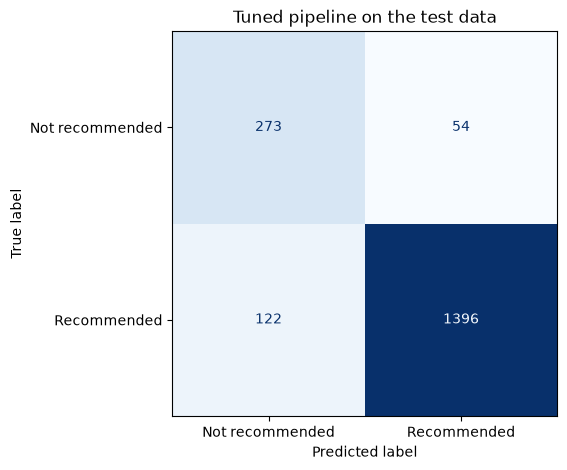

In [19]:
test_predictions = best_pipeline.predict(X_test)
print(classification_report(
    y_test, test_predictions,
    target_names=['Not recommended', 'Recommended'], digits=3))
print(pd.crosstab(y_test, test_predictions, rownames=['Actual'],
                  colnames=['Predicted']))

fig, ax = plt.subplots(figsize=(5, 5))
ConfusionMatrixDisplay.from_predictions(
    y_test, test_predictions,
    display_labels=['Not recommended', 'Recommended'],
    cmap='Blues', colorbar=False, ax=ax)
ax.set_title('Tuned pipeline on the test data')
plt.show()

### Which features does the model rely on?

The logistic regression gives every feature a weight. Positive weights push a prediction toward "recommended" and negative weights push it toward "not recommended".

Toward "not recommended": review: return, review: disappointed, review: want love, review: not flattering, review: huge, review: bad, review: cheap, review: excited, title: unflattering, title: not flattering, review: look like, review: shame, review: unflattering, title: horrible, review: maternity

Toward "recommended": review: perfect, review: comfortable, title: unique, title: fun, review: soft, review: love, review: great, review: size, title: comfortable, title: little, review: happy, review: compliment, title: soft, title: amazing, title: versatile


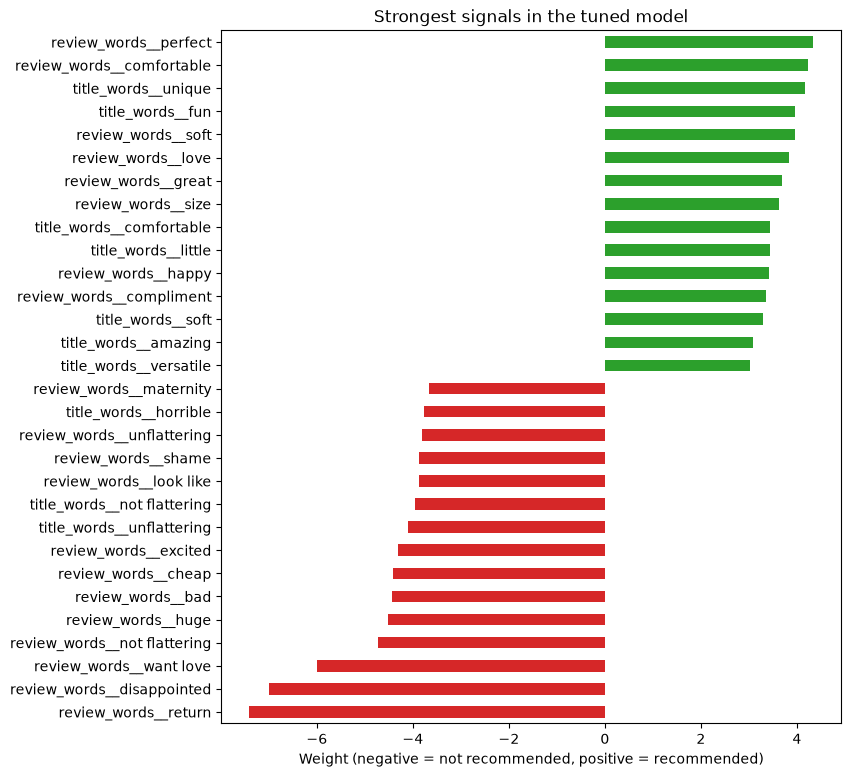

In [20]:
def top_features(fitted_pipeline, count=15):
    """Return the features with the largest positive and negative weights.

    Args:
        fitted_pipeline (sklearn.pipeline.Pipeline): The trained pipeline.
        count (int): How many features to return in each direction.

    Returns:
        pandas.Series: Weights indexed by feature name, sorted ascending.
    """
    names = fitted_pipeline.named_steps[
        'preprocess'].get_feature_names_out()
    weights = pd.Series(
        fitted_pipeline.named_steps['model'].coef_.ravel(), index=names)
    weights = weights.sort_values()
    return pd.concat([weights.head(count), weights.tail(count)])


weights = top_features(best_pipeline)
labels = [name.replace('_words__', ': ') for name in weights.index]
print('Toward "not recommended":', ', '.join(labels[:15]))
print('\nToward "recommended":', ', '.join(labels[:14:-1]))
colors = ['#d62728' if weight < 0 else '#2ca02c' for weight in weights]
ax = weights.plot(kind='barh', figsize=(8, 9), color=colors)
ax.set_title('Strongest signals in the tuned model')
ax.set_xlabel('Weight (negative = not recommended, '
              'positive = recommended)')
plt.show()

In [21]:
created = [name for name in best_pipeline.named_steps[
    'preprocess'].get_feature_names_out()
    if name.startswith(('review_statistics', 'review_grammar', 'numeric'))]
all_weights = pd.Series(
    best_pipeline.named_steps['model'].coef_.ravel(),
    index=best_pipeline.named_steps['preprocess'].get_feature_names_out())
print('Weights of the numeric and created features (scaled inputs):')
print(all_weights[created].sort_values().round(3))

Weights of the numeric and created features (scaled inputs):
review_statistics__character_count       -1.089
review_grammar__share_adv                -0.119
review_grammar__negation_count           -0.111
numeric__Positive Feedback Count         -0.106
review_statistics__question_count        -0.057
review_statistics__longest_word_length   -0.046
numeric__Age                              0.046
review_grammar__share_verb                0.085
review_grammar__share_noun                0.111
review_grammar__share_adj                 0.184
review_statistics__exclamation_count      0.258
review_statistics__word_count             1.295
dtype: float64


### Using the pipeline on new reviews

The same pipeline object handles inference. The second example has missing values, to show that the pipeline copes with gaps.

In [22]:
new_reviews = pd.DataFrame([
    {'Clothing ID': 1077, 'Age': 34, 'Title': 'Perfect fit',
     'Review Text': 'I love this dress. It is comfortable, flattering '
                    'and I get compliments every time I wear it!',
     'Positive Feedback Count': 2, 'Division Name': 'General',
     'Department Name': 'Dresses', 'Class Name': 'Dresses'},
    {'Clothing ID': 999999, 'Age': np.nan, 'Title': np.nan,
     'Review Text': 'The material felt cheap and it was not flattering '
                    'at all. I returned it.',
     'Positive Feedback Count': np.nan, 'Division Name': np.nan,
     'Department Name': 'Tops', 'Class Name': np.nan},
])[X_train.columns]
new_reviews['predicted'] = best_pipeline.predict(new_reviews)
new_reviews['probability_recommended'] = best_pipeline.predict_proba(
    new_reviews.drop(columns='predicted'))[:, 1].round(3)
new_reviews[['Review Text', 'predicted', 'probability_recommended']]

,Review Text,predicted,probability_recommended
0,"I love this dress. It is comfortable, flatteri...",1,0.996
1,The material felt cheap and it was not flatter...,0,0.005


## Conclusions

**Result on the test data (1,845 reviews the pipeline had never seen)**

| Model | Accuracy | Macro F1 | ROC AUC | Precision (not rec.) | Recall (not rec.) |
|---|---|---|---|---|---|
| Baseline (always recommended) | 0.823 | 0.451 | 0.500 | 0.000 | 0.000 |
| Pipeline (default settings) | 0.908 | 0.830 | 0.945 | 0.790 | 0.654 |
| Pipeline (tuned) | 0.905 | 0.848 | 0.947 | 0.691 | 0.835 |

* The tuned pipeline classifies 90.5% of the test reviews correctly, against 82.3% for the baseline.
* Tuning did not raise accuracy (0.905 against 0.908 for the default settings). What it changed is the balance between the two kinds of error. The tuned pipeline finds 83.5% of the reviews that do not recommend the product (273 of 327), where the default settings find 65.4%. The price is lower precision: 69.1% of the reviews it flags as "not recommended" really are, against 79.0%. If StyleSense cares most about finding the reviews that do not recommend a product, the higher recall is worth the lower precision. The business cost of each kind of error was not measured. Macro F1 rises from 0.830 to 0.848.
* The test macro F1 (0.848) is close to the cross-validated value from the search (0.851), so there is no large drop between validation and test on this split.

**What the model relies on**

* The strongest signals toward "not recommended" are words such as "return", "disappointed", "not flattering", "cheap" and "unflattering". The strongest toward "recommended" are "perfect", "comfortable", "soft", "love" and "great".
* "not flattering" is among the strongest negative signals in both the review text and the title. It exists as a feature only because negations were kept. The effect of keeping them on the scores was not measured separately.
* Some negative signals are less obvious. "want love" is what remains of phrases such as "wanted to love" after stop words are removed. "excited" also has a negative weight. One possible reason is reviewers describing how excited they were before the item arrived, but the reviews were not inspected to confirm it.
* Among the created features, a higher share of adjectives (+0.18) and more exclamation marks (+0.26) point toward "recommended", and more negations (-0.11) point toward "not recommended". Character count and word count get large weights with opposite signs. The two are closely related, so they should be read together and not one at a time.

**Limitations**

* The result comes from a single test split of 1,845 reviews, of which 327 do not recommend the product. Figures for that class may change on a different split, and their uncertainty was not estimated.
* The weights show what the model associates with each class. They do not show why customers were unhappy.
* Only one type of model was tuned, and the 0.5 probability cut-off was left as it is. Moving the cut-off would be the simplest way to trade recall against precision further.
* The model was trained on reviews that already had an answer. If the reviews with a missing answer differ in some way, for example if unhappy customers skip the question more often, performance on them could be lower.